In [ ]:
import datetime as dt
from datetime import date, datetime
from pathlib import Path
from zoneinfo import ZoneInfo

import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import polars_h3 as plh3
import seaborn as sns
import yaml

from common import daterange, read_day

with open("../config.yaml", "r") as fp:
    config = yaml.safe_load(fp)

In [2]:
sep9 = read_day(date(2025, 9, 9), config["dirs"]["pickwell"])
sep9 = sep9.with_columns(pl.from_epoch(pl.col("timestamp"), time_unit="s"))

In [3]:
sep9_by_min = (
    sep9.sort("timestamp")
    .group_by_dynamic("timestamp", every="1m", closed="right")
    .agg(pl.col("device_aid_hashed").count())
    .sort("timestamp")
    .rename({"device_aid_hashed": "count"})
)

In [4]:
sep9_by_min.write_csv("../output/debug/sep9_by_min.csv")

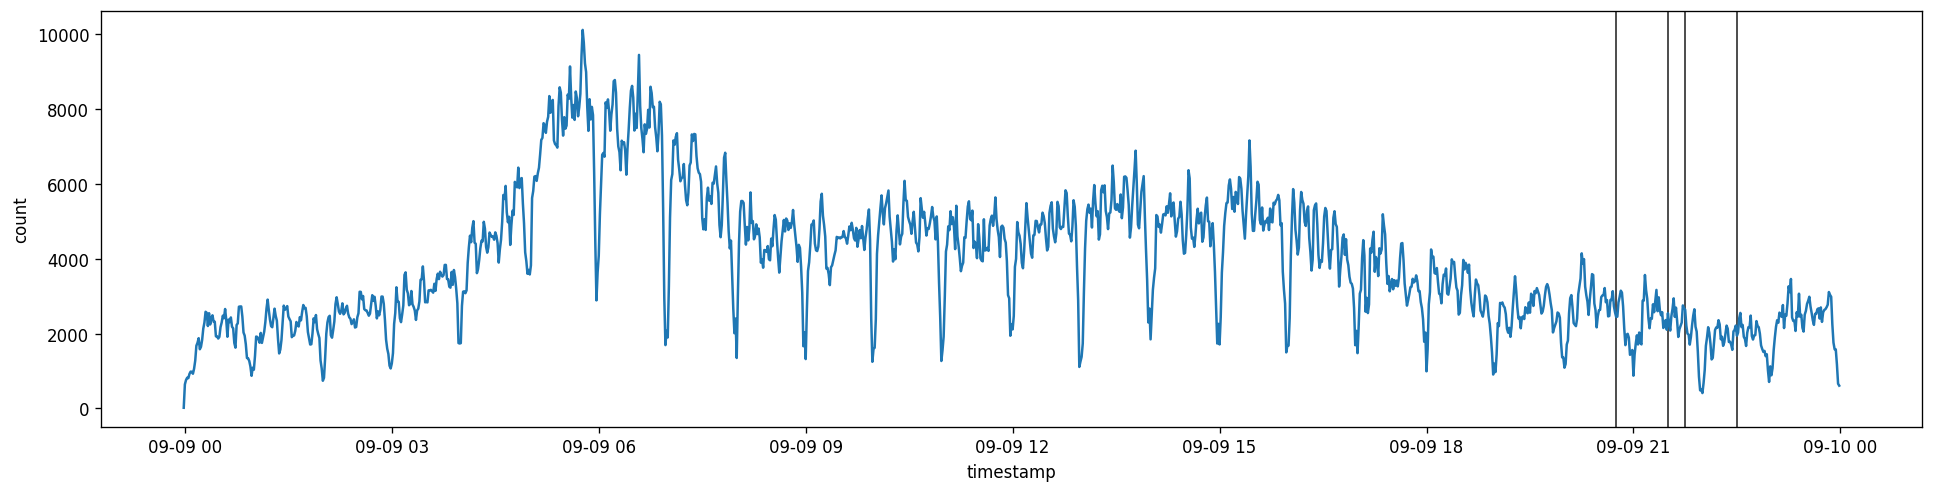

In [5]:
fig, ax = plt.subplots(layout="constrained", figsize=(16, 4), dpi=120)
sns.lineplot(
    data=sep9_by_min,
    x="timestamp",
    y="count",
    ax=ax,
)
ax.axvline(
    datetime(2025, 9, 9, 20, 45, tzinfo=dt.timezone.utc),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)
ax.axvline(
    datetime(2025, 9, 9, 21, 30, tzinfo=dt.timezone.utc),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)
ax.axvline(
    datetime(2025, 9, 9, 21, 45, tzinfo=dt.timezone.utc),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)
ax.axvline(
    datetime(2025, 9, 9, 22, 30, tzinfo=dt.timezone.utc),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)

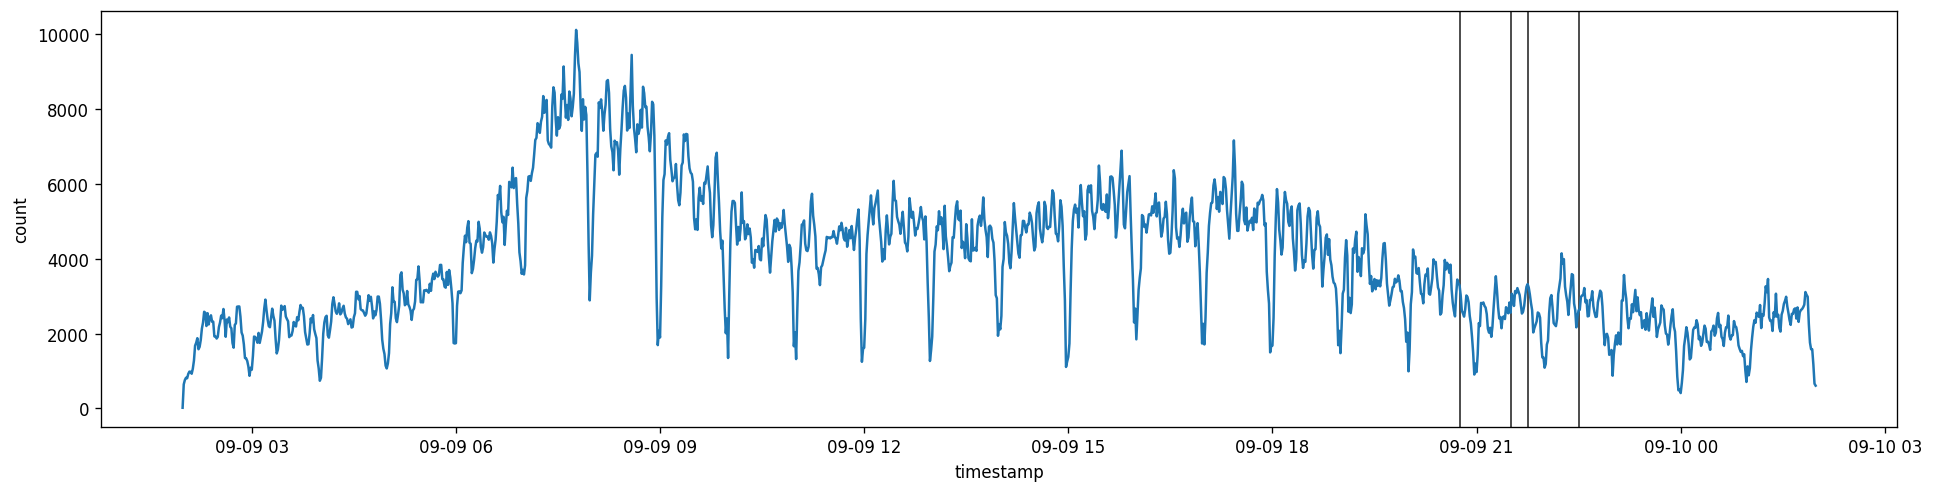

In [6]:
fig, ax = plt.subplots(layout="constrained", figsize=(16, 4), dpi=120)
sns.lineplot(
    data=sep9_by_min.with_columns(
        timestamp=pl.col("timestamp").dt.convert_time_zone(time_zone="Europe/Budapest"),
    ),
    x="timestamp",
    y="count",
    ax=ax,
)
ax.axvline(
    datetime(2025, 9, 9, 20, 45, tzinfo=ZoneInfo("Europe/Budapest")),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)
ax.axvline(
    datetime(2025, 9, 9, 21, 30, tzinfo=ZoneInfo("Europe/Budapest")),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)
ax.axvline(
    datetime(2025, 9, 9, 21, 45, tzinfo=ZoneInfo("Europe/Budapest")),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)
ax.axvline(
    datetime(2025, 9, 9, 22, 30, tzinfo=ZoneInfo("Europe/Budapest")),
    linestyle="solid",
    lw=1,
    color="#2d2d2d",
    zorder=1,
)

In [7]:
sziget = pl.DataFrame()
for i in daterange(date(2025, 8, 6), date(2025, 8, 11)):
    temp = read_day(i, config["dirs"]["pickwell"])
    sziget = pl.concat([sziget, temp])
sziget = sziget.with_columns(pl.from_epoch(pl.col("timestamp"), time_unit="s"))

In [8]:
sziget_by_15min = (
    sziget.sort("timestamp")
    .group_by_dynamic("timestamp", every="15m", closed="right")
    .agg(pl.col("device_aid_hashed").count())
    .sort("timestamp")
    .rename({"device_aid_hashed": "count"})
)

<Axes: xlabel='timestamp', ylabel='count'>

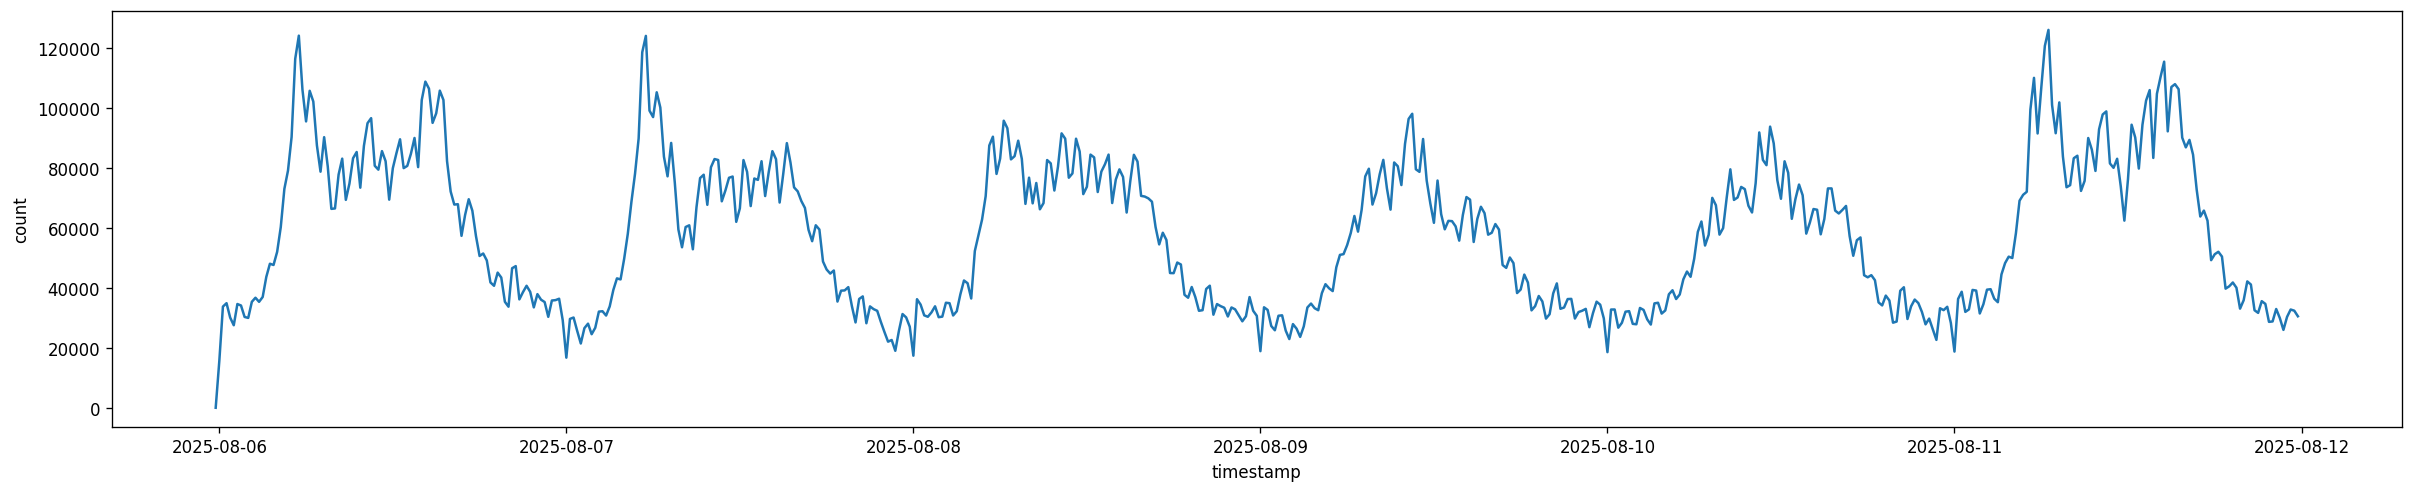

In [9]:
fig, ax = plt.subplots(layout="constrained", figsize=(20, 4), dpi=120)
sns.lineplot(
    data=sziget_by_15min,
    x="timestamp",
    y="count",
    ax=ax,
)

In [10]:
sziget_by_15min_ud = (
    sziget.sort("timestamp")
    .group_by_dynamic("timestamp", every="15m", closed="right")
    .agg(pl.col("device_aid_hashed").unique().count())
    .sort("timestamp")
    .rename({"device_aid_hashed": "count"})
)

<Axes: xlabel='timestamp', ylabel='count'>

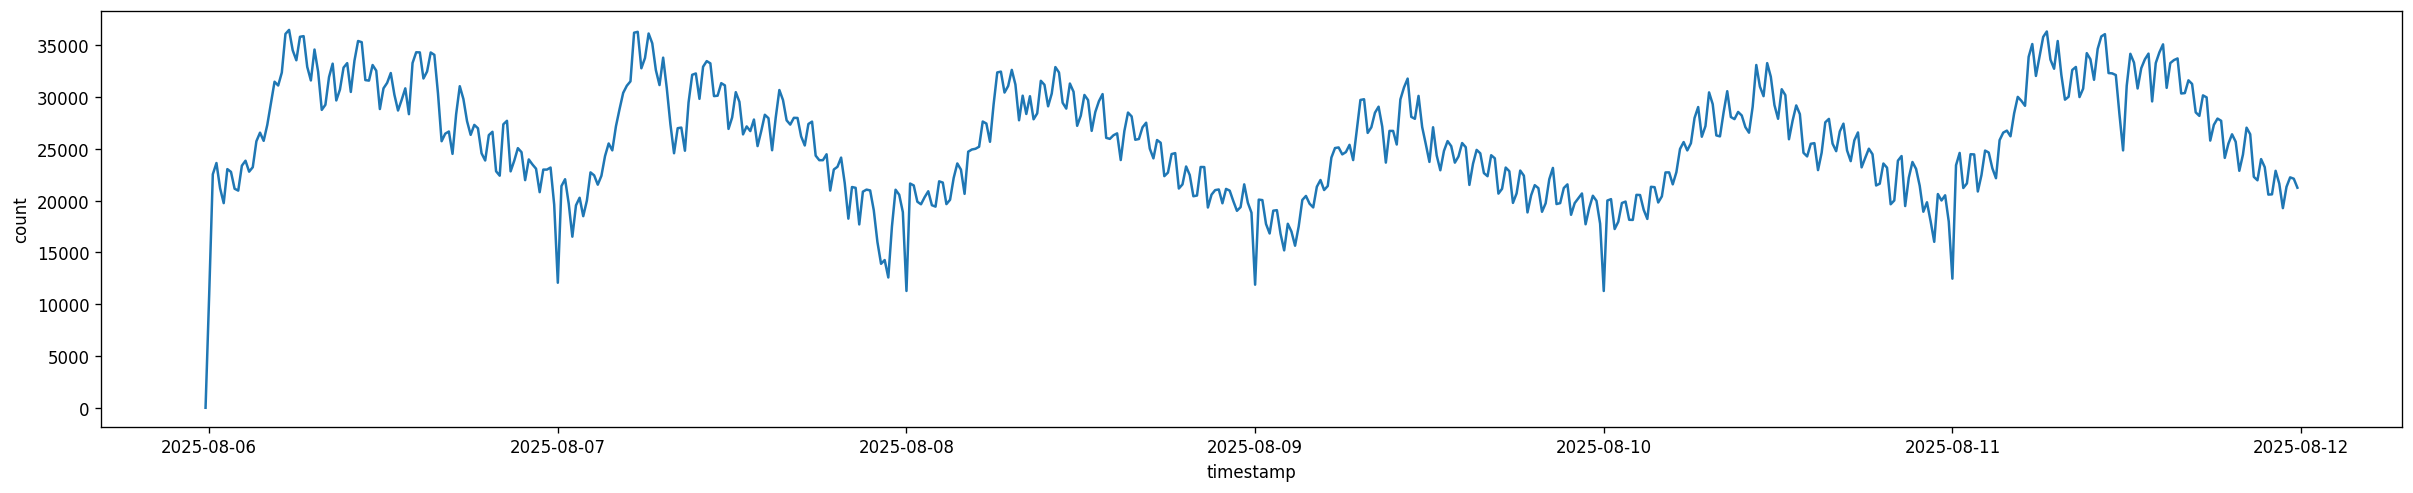

In [11]:
fig, ax = plt.subplots(layout="constrained", figsize=(20, 4), dpi=120)
sns.lineplot(
    data=sziget_by_15min_ud,
    x="timestamp",
    y="count",
    ax=ax,
)

In [12]:
hexagons_9 = gpd.read_file("../data/h3/budapest/9.geojson").to_crs(23700)

In [13]:
area = gpd.read_file("../data/area.geojson").to_crs(23700).geometry[0]

In [14]:
def half_hour_times():
    times = []
    for minutes in range(0, 24 * 60, 30):
        hh = minutes // 60
        mm = minutes % 60
        times.append(f"{hh:02d}:{mm:02d}")
    return times

In [15]:
import itertools

In [16]:
def cartesian_product_df(a, b, col_a="h3_9", col_b="timestamp"):
    pairs = [(x, y) for x, y in itertools.product(a, b)]
    return pl.DataFrame(pairs, schema=[col_a, col_b], orient="row")

In [17]:
empty = cartesian_product_df(hexagons_9["h3"], half_hour_times())
empty = empty.with_columns(pl.lit(0).alias("count"))

In [18]:
DIR = "/mnt/common-hdd/group-dirs/tkom-2026-project/cleaned/"
dd = pl.DataFrame()
for i in daterange(date(2025, 10, 20), date(2025, 10, 26)):
    data = pl.read_csv(Path(f"{DIR}/{i.strftime('%Y/%m/%d')}/locations.csv"))
    data = data.with_columns(
        plh3.int_to_str(
            plh3.latlng_to_cell(pl.col("latitude"), pl.col("longitude"), 9)
        ).alias("h3_9"),
        plh3.int_to_str(
            plh3.latlng_to_cell(pl.col("latitude"), pl.col("longitude"), 10)
        ).alias("h3_10"),
    )
    dd = pl.concat([dd, data])
dd = dd.with_columns(pl.col("timestamp").str.to_datetime("%Y-%m-%d %H:%M:%S"))

In [19]:
oct23_h9 = (
    dd.sort("timestamp")
    .group_by_dynamic("timestamp", every="30m", closed="right", group_by=["h3_9"])
    .agg(pl.col("device_id").unique().count())
    .sort("timestamp")
    .rename({"device_id": "count"})
).filter(
    pl.col("timestamp").is_between(
        datetime(2025, 10, 23), datetime(2025, 10, 23, 23, 59, 59)
    )
)
oct24_h9 = (
    dd.sort("timestamp")
    .group_by_dynamic("timestamp", every="30m", closed="right", group_by=["h3_9"])
    .agg(pl.col("device_id").unique().count())
    .sort("timestamp")
    .rename({"device_id": "count"})
).filter(
    pl.col("timestamp").is_between(
        datetime(2025, 10, 24), datetime(2025, 10, 24, 23, 59, 59)
    )
)

In [20]:
ref_h9 = (
    dd.sort("timestamp")
    .group_by_dynamic("timestamp", every="30m", closed="right", group_by=["h3_9"])
    .agg(pl.col("device_id").unique().count())
    .sort("timestamp")
    .rename({"device_id": "count"})
).filter(
    (
        pl.col("timestamp").is_between(
            datetime(2025, 10, 20), datetime(2025, 10, 22, 23, 59, 59)
        )
    )
    | (
        pl.col("timestamp").is_between(
            datetime(2025, 10, 25), datetime(2025, 10, 26, 23, 59, 59)
        )
    )
)

In [21]:
ref_mean = (
    ref_h9.with_columns(pl.col("timestamp").dt.strftime("%H:%M"))
    .group_by(["h3_9", "timestamp"])
    .agg(pl.col("count").mean())
    .sort(["h3_9", "timestamp"])
    # .rename({"h3_9": "h3"})
    .rename({"count": "mean"})
)
ref_std = (
    ref_h9.with_columns(pl.col("timestamp").dt.strftime("%H:%M"))
    .group_by(["h3_9", "timestamp"])
    .agg(pl.col("count").std())
    .sort(["h3_9", "timestamp"])
    # .rename({"h3_9": "h3"})
    .rename({"count": "std"})
)

In [43]:
act_o23 = (
    oct23_h9.with_columns(pl.col("timestamp").dt.strftime("%H:%M"))
    .group_by(["h3_9", "timestamp"])
    .agg(pl.col("count").sum())
    .sort(["h3_9", "timestamp"])
    .rename({"count": "oct23"})
    .with_columns(pl.col("oct23").cast(pl.Int32))
)
act_o23 = pl.concat([empty.rename({"count": "oct23"}), act_o23]).unique(
    ["h3_9", "timestamp"], keep="last"
)

In [45]:
ao23 = (
    act_o23.join(ref_mean, on=["h3_9", "timestamp"], how="left")
    .join(ref_std, on=["h3_9", "timestamp"], how="left")
    .fill_null(0)
)
ao23 = ao23.with_columns(z_score=(pl.col("oct23") - pl.col("mean")) / pl.col("std"))
ao23 = ao23.with_columns(pl.col("z_score").replace({-np.inf: np.nan, np.inf: np.nan}))

In [22]:
act_o24 = (
    oct24_h9.with_columns(pl.col("timestamp").dt.strftime("%H:%M"))
    .group_by(["h3_9", "timestamp"])
    .agg(pl.col("count").sum())
    .sort(["h3_9", "timestamp"])
    .rename({"count": "oct24"})
    .with_columns(pl.col("oct24").cast(pl.Int32))
)
act_o24 = pl.concat([empty.rename({"count": "oct24"}), act_o24]).unique(
    ["h3_9", "timestamp"], keep="last"
)

In [ ]:
ao24 = (
    act_o24.join(ref_mean, on=["h3_9", "timestamp"], how="left")
    .join(ref_std, on=["h3_9", "timestamp"], how="left")
    .fill_null(0)
)
ao24 = ao24.with_columns(z_score=(pl.col("oct24") - pl.col("mean")) / pl.col("std"))
ao24 = ao24.with_columns(pl.col("z_score").replace({-np.inf: np.nan, np.inf: np.nan}))

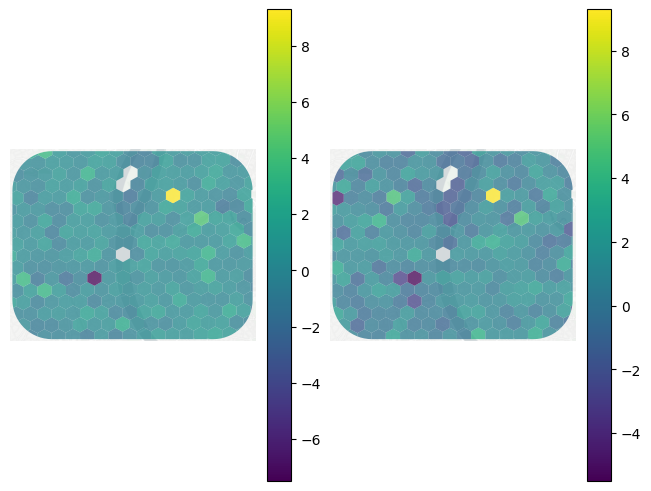

In [48]:
fig, axs = plt.subplots(layout="constrained", ncols=2)
for a in axs:
    a.axis("off")
    a.margins(0.01)
gpd.clip(
    hexagons_9.merge(
        ao23.filter(pl.col("timestamp") == "10:30").rename({"h3_9": "h3"}).to_pandas()
    ),
    area.buffer(1000),
).plot(ax=axs[0], column="z_score", legend=True, alpha=0.75)
gpd.clip(
    hexagons_9.merge(
        ao24.filter(pl.col("timestamp") == "10:30").rename({"h3_9": "h3"}).to_pandas()
    ),
    area.buffer(1000),
).plot(ax=axs[1], column="z_score", legend=True, alpha=0.75)
cx.add_basemap(
    axs[0],
    crs=23700,
    source=cx.providers.CartoDB.PositronNoLabels,  # light
    alpha=1,
    attribution=False,
)
cx.add_basemap(
    axs[1],
    crs=23700,
    source=cx.providers.CartoDB.PositronNoLabels,  # light
    alpha=1,
    attribution=False,
)

/mnt/common-ssd/pintergreg/wp7_data_processing/.venv/lib/python3.13/site-packages/matplotlib/colors.py:2294: RuntimeWarning: invalid value encountered in subtract
  resdat -= vmin
/mnt/common-ssd/pintergreg/wp7_data_processing/.venv/lib/python3.13/site-packages/matplotlib/colors.py:2295: RuntimeWarning: invalid value encountered in divide
  resdat /= (vmax - vmin)


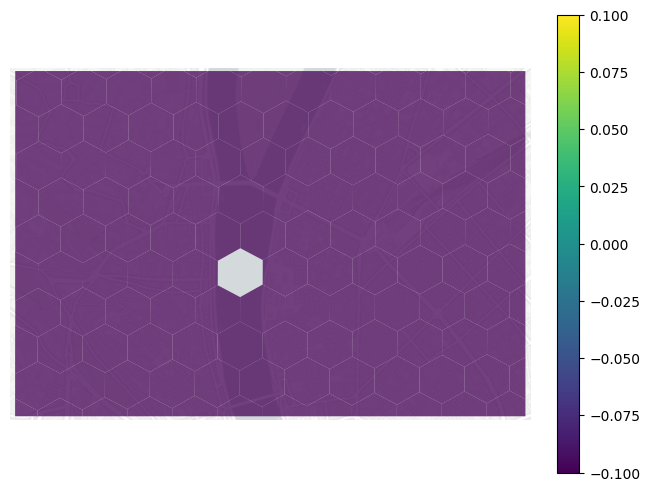

In [ ]:
fig, ax = plt.subplots(layout="constrained")
ax.axis("off")
ax.margins(0.01)
gpd.clip(
    hexagons_9.merge(
        ao24.filter(pl.col("timestamp") == "10:00").rename({"h3_9": "h3"}).to_pandas()
    ),
    area,
).plot(
    ax=ax,
    column="z_score",
    legend=True,
    alpha=0.75,
)
cx.add_basemap(
    ax,
    crs=23700,
    source=cx.providers.CartoDB.PositronNoLabels,  # light
    alpha=1,
    attribution=False,
)

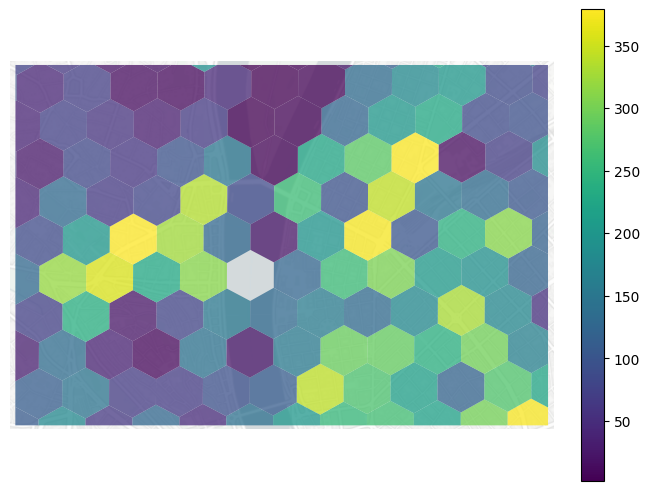

In [ ]:
fig, ax = plt.subplots(layout="constrained")
ax.axis("off")
ax.margins(0.01)
gpd.clip(
    hexagons_9.merge(
        oct24_h9.filter(
            pl.col("timestamp").is_between(
                datetime(2025, 10, 24, 8), datetime(2025, 10, 24, 10)
            )
        )
        .group_by(pl.col.h3_9)
        .agg(pl.col("count").sum())
        .rename({"h3_9": "h3"})
        .to_pandas()
    ),
    area,
).plot(
    ax=ax,
    column="count",
    legend=True,
    alpha=0.75,
)
cx.add_basemap(
    ax,
    crs=23700,
    source=cx.providers.CartoDB.PositronNoLabels,  # light
    alpha=1,
    attribution=False,
)